# Facebook Metrics — Exploratory Data Analysis

**Goal:** understand what drives the performance of Facebook posts: which post types, categories and publishing times get the most reach and engagement, and how the engagement metrics relate to each other.

**Dataset:** *Facebook metrics* (Moro, Rita & Vala, 2016; UCI Machine Learning Repository, also on Kaggle as *masoodanzar/facebook-metrics*). 500 posts published in 2014 on the Facebook page of a well-known cosmetics brand.

**Tools:** pandas, NumPy, Matplotlib, Seaborn.

## 1. Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 25)

raw = pd.read_csv('data/dataset_Facebook.csv', sep=';')
raw.head()

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393


In [2]:
raw.shape

(500, 19)

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Page total likes                                                     500 non-null    int64  
 1   Type                                                                 500 non-null    object 
 2   Category                                                             500 non-null    int64  
 3   Post Month                                                           500 non-null    int64  
 4   Post Weekday                                                         500 non-null    int64  
 5   Post Hour                                                            500 non-null    int64  
 6   Paid                                                                 499 non-null    float64
 7   Lifetime

The long original column names are shortened to make the code easier to read.

In [4]:
df = raw.rename(columns={
    'Page total likes': 'page_likes', 'Type': 'type', 'Category': 'category',
    'Post Month': 'month', 'Post Weekday': 'weekday', 'Post Hour': 'hour', 'Paid': 'paid',
    'Lifetime Post Total Reach': 'reach', 'Lifetime Post Total Impressions': 'impressions',
    'Lifetime Engaged Users': 'engaged_users', 'Lifetime Post Consumers': 'consumers',
    'Lifetime Post Consumptions': 'consumptions',
    'Lifetime Post Impressions by people who have liked your Page': 'impressions_fans',
    'Lifetime Post reach by people who like your Page': 'reach_fans',
    'Lifetime People who have liked your Page and engaged with your post': 'engaged_fans',
    'comment': 'comments', 'like': 'likes', 'share': 'shares', 'Total Interactions': 'interactions'})
df.columns.tolist()

['page_likes',
 'type',
 'category',
 'month',
 'weekday',
 'hour',
 'paid',
 'reach',
 'impressions',
 'engaged_users',
 'consumers',
 'consumptions',
 'impressions_fans',
 'reach_fans',
 'engaged_fans',
 'comments',
 'likes',
 'shares',
 'interactions']

## 2. Data cleaning
### 2.1 Missing values

In [5]:
df.isna().sum()[df.isna().sum() > 0]

paid      1
likes     1
shares    4
dtype: int64

In [6]:
df[df.isna().any(axis=1)]

,page_likes,type,category,month,weekday,hour,paid,reach,impressions,engaged_users,consumers,consumptions,impressions_fans,reach_fans,engaged_fans,comments,likes,shares,interactions
111,136736,Photo,1,10,6,8,0.0,1261,2158,37,37,49,1911,1077,33,0,NaN,NaN,0
120,136393,Photo,1,10,7,9,0.0,584,1029,273,271,308,943,511,232,0,2.0,NaN,2
124,136393,Photo,1,10,7,6,0.0,677,1285,251,246,297,1210,615,211,0,7.0,NaN,7
164,135428,Photo,1,9,5,10,0.0,1060,2004,266,251,337,1705,870,204,0,18.0,NaN,18
499,81370,Photo,2,1,4,4,NaN,4188,7292,564,524,743,3861,2200,316,0,91.0,28.0,119


Only 5 values are missing (1 `paid`, 1 `likes`, 4 `shares`). We fill `likes` and `shares` with 0 — this is reasonable because `interactions` should equal comments + likes + shares and we can check it. The one missing `paid` flag is filled with the most common value (0 = not paid).

In [7]:
df['likes'] = df['likes'].fillna(0)
df['shares'] = df['shares'].fillna(0)
df['paid'] = df['paid'].fillna(df['paid'].mode()[0])

check = df['comments'] + df['likes'] + df['shares'] - df['interactions']
print('Rows where interactions != comments + likes + shares:', (check != 0).sum())
df.isna().sum().sum()

Rows where interactions != comments + likes + shares: 0


np.int64(0)

### 2.2 Duplicates and data types

In [8]:
print('Duplicate rows:', df.duplicated().sum())
category_names = {1: 'Action (offers)', 2: 'Product (ads)', 3: 'Inspiration'}
df['category_name'] = df['category'].map(category_names)
df['paid'] = df['paid'].astype(int).map({0: 'Organic', 1: 'Paid'})
for col in ['likes', 'shares']:
    df[col] = df[col].astype(int)
df['type'] = df['type'].astype('category')
df.dtypes

Duplicate rows: 0


page_likes             int64
type                category
category               int64
month                  int64
weekday                int64
hour                   int64
paid                  object
reach                  int64
impressions            int64
engaged_users          int64
consumers              int64
consumptions           int64
impressions_fans       int64
reach_fans             int64
engaged_fans           int64
comments               int64
likes                  int64
shares                 int64
interactions           int64
category_name         object
dtype: object

### 2.3 Derived metrics
Raw counts depend on how many people saw a post, so we also use **rates**:
- `engagement_rate` = engaged users ÷ reach × 100
- `interaction_rate` = interactions ÷ reach × 100
- `virality` = shares ÷ interactions × 100

In [9]:
df['engagement_rate'] = df['engaged_users'] / df['reach'] * 100
df['interaction_rate'] = df['interactions'] / df['reach'] * 100
df['virality'] = np.where(df['interactions'] > 0, df['shares'] / df['interactions'] * 100, 0)
df[['reach', 'engaged_users', 'interactions', 'engagement_rate', 'interaction_rate', 'virality']].head()

,reach,engaged_users,interactions,engagement_rate,interaction_rate,virality
0,2752,178,100,6.468023,3.633721,17.000000
1,10460,1457,164,13.929254,1.567878,17.682927
2,2413,177,80,7.335267,3.315375,17.500000
3,50128,2211,1777,4.410709,3.544925,8.272369
4,7244,671,393,9.262838,5.425179,12.468193


## 3. Descriptive statistics

In [10]:
df[['reach', 'impressions', 'engaged_users', 'comments', 'likes', 'shares', 'interactions', 'engagement_rate']].describe().round(1)

,reach,impressions,engaged_users,comments,likes,shares,interactions,engagement_rate
count,500.0,500.0,500.0,500.0,500.0,500.0,500.0,500.0
mean,13903.4,29585.9,920.3,7.5,177.6,27.0,212.1,12.4
std,22740.8,76803.2,985.0,21.2,323.2,42.5,380.2,8.1
min,238.0,570.0,9.0,0.0,0.0,0.0,0.0,0.5
25%,3315.0,5694.8,393.8,1.0,56.0,10.0,71.0,6.4
50%,5281.0,9051.0,625.5,3.0,101.0,19.0,123.5,12.2
75%,13168.0,22085.5,1062.0,7.0,187.2,32.0,228.5,16.3
max,180480.0,1110282.0,11452.0,372.0,5172.0,790.0,6334.0,60.1


In [11]:
for col in ['reach', 'impressions', 'interactions']:
    print(f"{col:13s} mean {df[col].mean():>9,.0f}  median {df[col].median():>8,.0f}  skew {df[col].skew():5.1f}")
print()
print('Share of posts by type:'); print((df['type'].value_counts(normalize=True) * 100).round(1))

reach         mean    13,903  median    5,281  skew   3.7


impressions   mean    29,586  median    9,051  skew   8.4
interactions  mean       212  median      124  skew   9.7

Share of posts by type:
type
Photo     85.2
Status     9.0
Link       4.4
Video      1.4
Name: proportion, dtype: float64


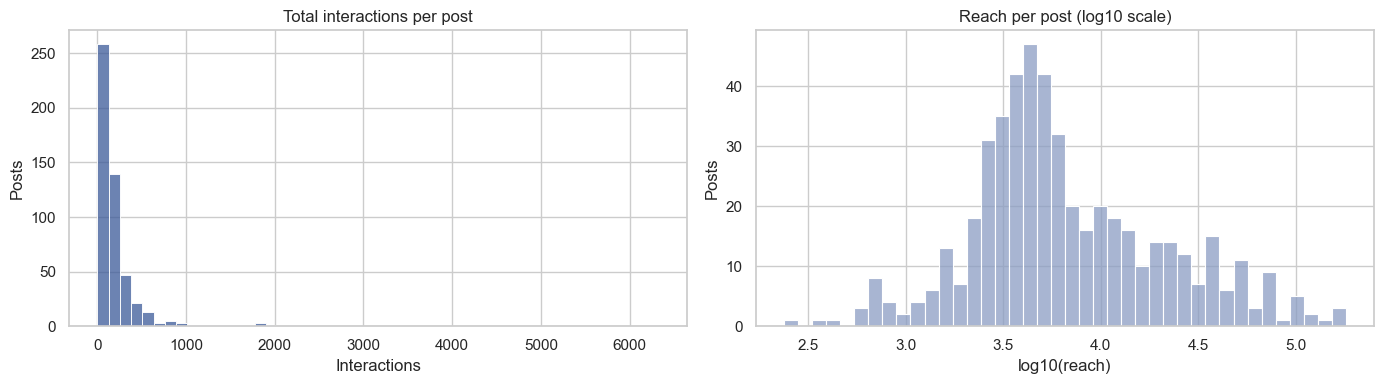

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['interactions'], bins=50, ax=axes[0], color='#3b5998')
axes[0].set(title='Total interactions per post', xlabel='Interactions', ylabel='Posts')
sns.histplot(np.log10(df['reach']), bins=40, ax=axes[1], color='#8b9dc3')
axes[1].set(title='Reach per post (log10 scale)', xlabel='log10(reach)', ylabel='Posts')
plt.tight_layout(); plt.show()

The distributions are strongly right-skewed: a few posts get very large reach and interactions. We therefore compare **medians** as well as means.

## 4. Performance by post type

In [13]:
by_type = df.groupby('type', observed=True).agg(
    posts=('reach', 'size'), median_reach=('reach', 'median'), median_interactions=('interactions', 'median'),
    mean_interactions=('interactions', 'mean'), median_engagement_rate=('engagement_rate', 'median'),
    median_shares=('shares', 'median')).round(1)
by_type.sort_values('median_interactions', ascending=False)

,posts,median_reach,median_interactions,mean_interactions,median_engagement_rate,median_shares
type,,,,,,
Video,7,30624.0,271.0,295.9,3.2,44.0
Status,45,11096.0,186.0,217.0,15.5,28.0
Photo,426,4675.0,122.0,216.6,12.3,19.0
Link,22,7422.0,52.5,89.0,2.3,10.5


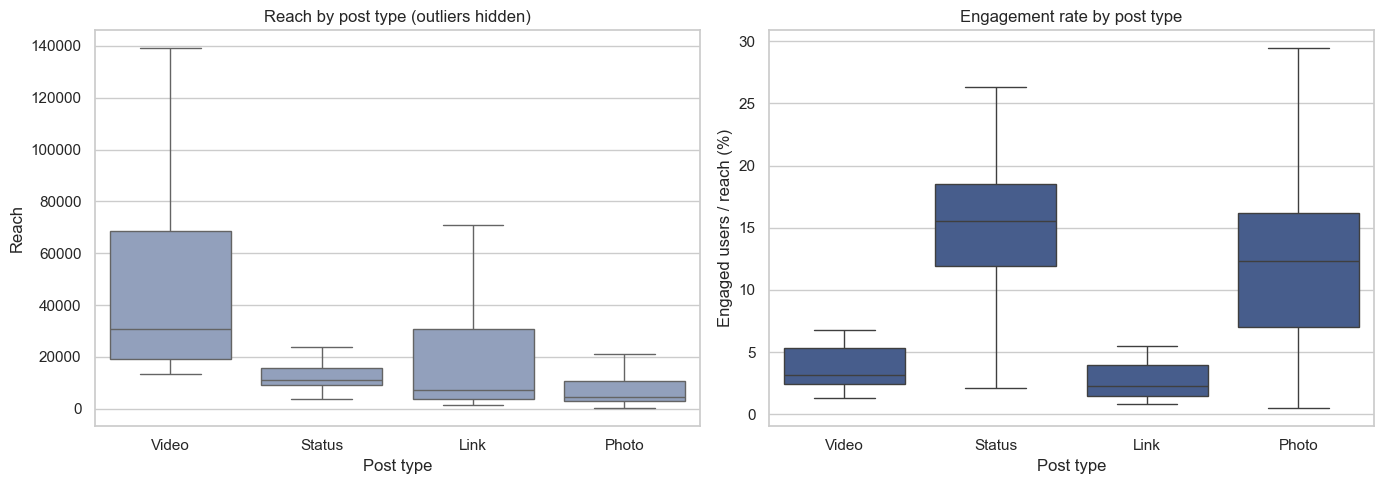

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = by_type.sort_values('median_reach', ascending=False).index
sns.boxplot(data=df, x='type', y='reach', order=order, ax=axes[0], showfliers=False, color='#8b9dc3')
axes[0].set(title='Reach by post type (outliers hidden)', xlabel='Post type', ylabel='Reach')
sns.boxplot(data=df, x='type', y='engagement_rate', order=order, ax=axes[1], showfliers=False, color='#3b5998')
axes[1].set(title='Engagement rate by post type', xlabel='Post type', ylabel='Engaged users / reach (%)')
plt.tight_layout(); plt.show()

## 5. Performance by category

In [15]:
by_cat = df.groupby('category_name').agg(
    posts=('reach', 'size'), median_reach=('reach', 'median'), median_interactions=('interactions', 'median'),
    median_engagement_rate=('engagement_rate', 'median'), median_virality=('virality', 'median')).round(1)
by_cat

,posts,median_reach,median_interactions,median_engagement_rate,median_virality
category_name,,,,,
Action (offers),215,5880.0,87.0,9.1,12.5
Inspiration,155,4800.0,163.0,13.3,16.1
Product (ads),130,5244.0,153.0,14.3,14.9


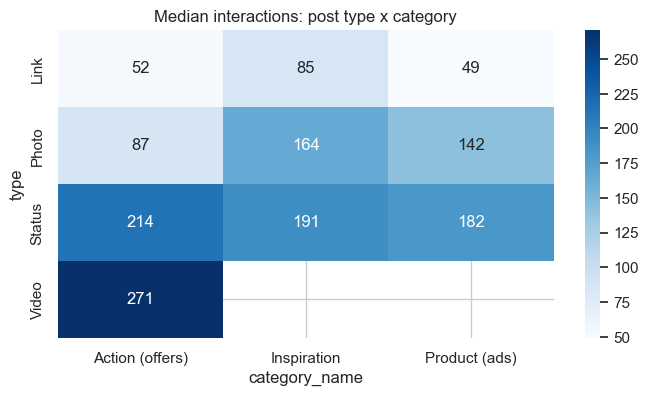

category_name,Action (offers),Inspiration,Product (ads)
type,,,
Link,20,1,1
Photo,185,150,91
Status,3,4,38
Video,7,0,0


In [16]:
pivot = df.pivot_table(index='type', columns='category_name', values='interactions', aggfunc='median', observed=True)
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues', ax=ax)
ax.set_title('Median interactions: post type x category')
plt.show()
pd.crosstab(df['type'], df['category_name'])

## 6. Paid vs organic posts

In [17]:
paid = df.groupby('paid').agg(posts=('reach', 'size'), median_reach=('reach', 'median'),
                             median_impressions=('impressions', 'median'), median_interactions=('interactions', 'median'),
                             median_engagement_rate=('engagement_rate', 'median')).round(1)
paid

,posts,median_reach,median_impressions,median_interactions,median_engagement_rate
paid,,,,,
Organic,361,4898.0,8387.0,117.0,12.3
Paid,139,7132.0,12060.0,158.0,11.8


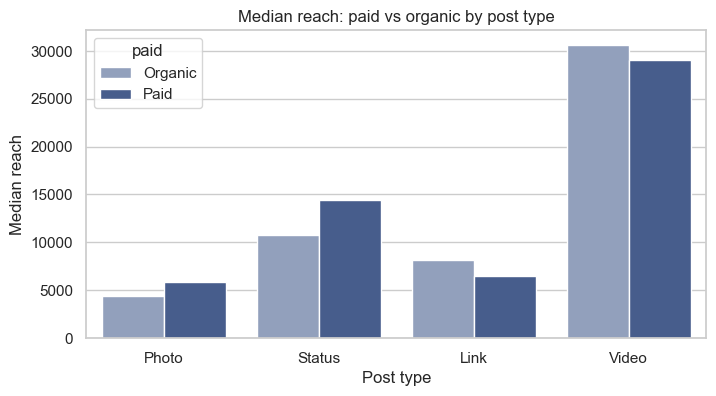

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x='type', y='reach', hue='paid', estimator=np.median, errorbar=None, ax=ax,
            order=['Photo', 'Status', 'Link', 'Video'], palette=['#8b9dc3', '#3b5998'])
ax.set(title='Median reach: paid vs organic by post type', xlabel='Post type', ylabel='Median reach')
plt.show()

## 7. Publication time

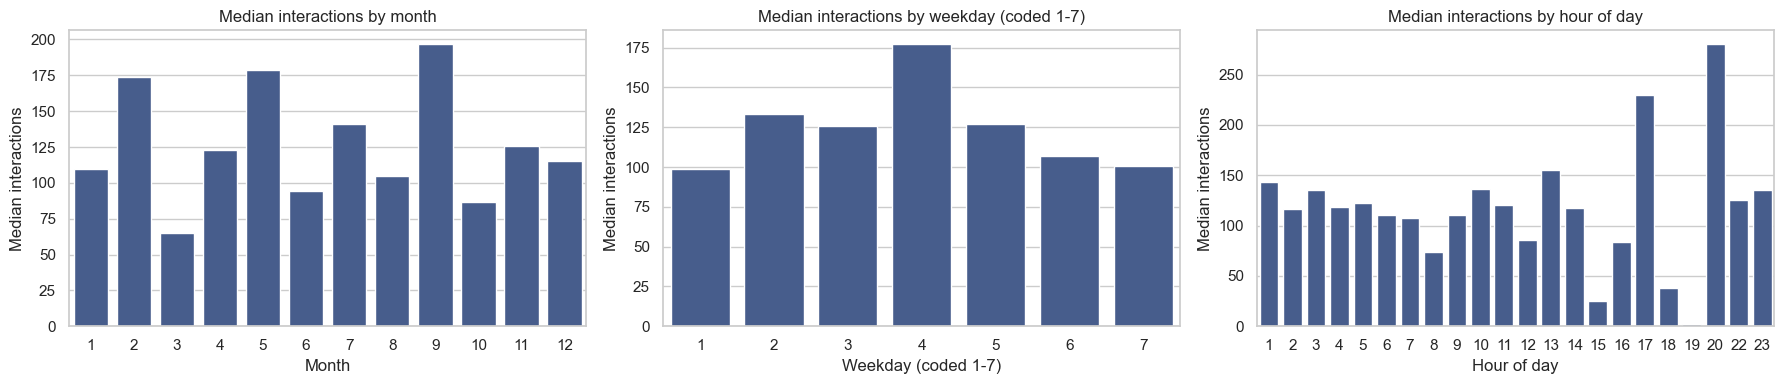

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, title in zip(axes, ['month', 'weekday', 'hour'], ['Month', 'Weekday (coded 1-7)', 'Hour of day']):
    g = df.groupby(col)['interactions'].median()
    sns.barplot(x=g.index, y=g.values, ax=ax, color='#3b5998')
    ax.set(title=f'Median interactions by {title.lower()}', xlabel=title, ylabel='Median interactions')
plt.tight_layout(); plt.show()

In [20]:
hour_stats = df.groupby('hour').agg(posts=('reach', 'size'), median_interactions=('interactions', 'median'),
                                   median_engagement_rate=('engagement_rate', 'median')).round(1)
print('Hours with at least 10 posts:')
hour_stats[hour_stats['posts'] >= 10].sort_values('median_interactions', ascending=False)

Hours with at least 10 posts:


,posts,median_interactions,median_engagement_rate
hour,,,
13,52,155.5,12.1
10,78,136.0,10.9
3,105,135.0,11.4
5,13,122.0,11.7
11,44,120.0,11.9
4,35,119.0,12.8
14,13,118.0,13.3
2,39,117.0,11.6
6,16,110.5,10.5


In [21]:
month_stats = df.groupby('month').agg(posts=('reach', 'size'), page_likes=('page_likes', 'max'),
                                     median_reach=('reach', 'median'), median_interactions=('interactions', 'median'))
month_stats

,posts,page_likes,median_reach,median_interactions
month,,,,
1,25,86909,5400.0,110.0
2,26,93684,8928.0,174.0
3,36,104070,5222.0,65.0
4,50,115893,6266.0,123.0
5,37,121540,5016.0,179.0
6,49,126424,4644.0,94.0
7,52,131808,5653.0,141.0
8,34,133679,4685.0,105.0
9,36,135700,4329.0,196.5


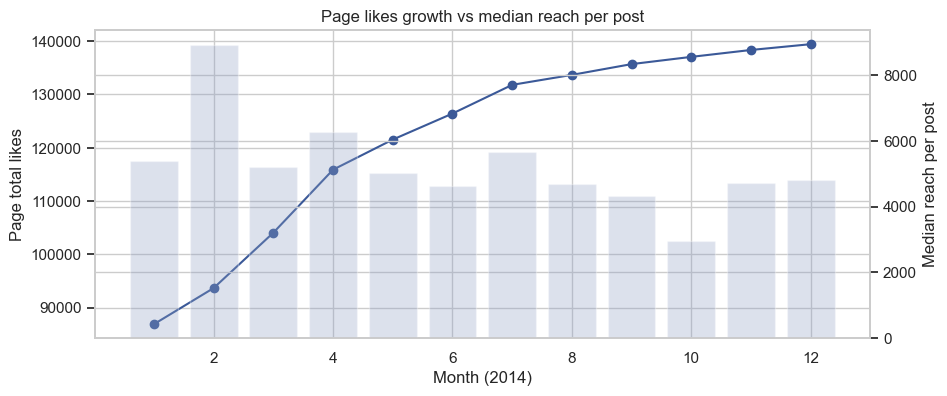

In [22]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(month_stats.index, month_stats['page_likes'], marker='o', color='#3b5998')
ax1.set(xlabel='Month (2014)', ylabel='Page total likes', title='Page likes growth vs median reach per post')
ax2 = ax1.twinx()
ax2.bar(month_stats.index, month_stats['median_reach'], alpha=0.3, color='#8b9dc3')
ax2.set_ylabel('Median reach per post')
plt.show()

## 8. Relationships between metrics

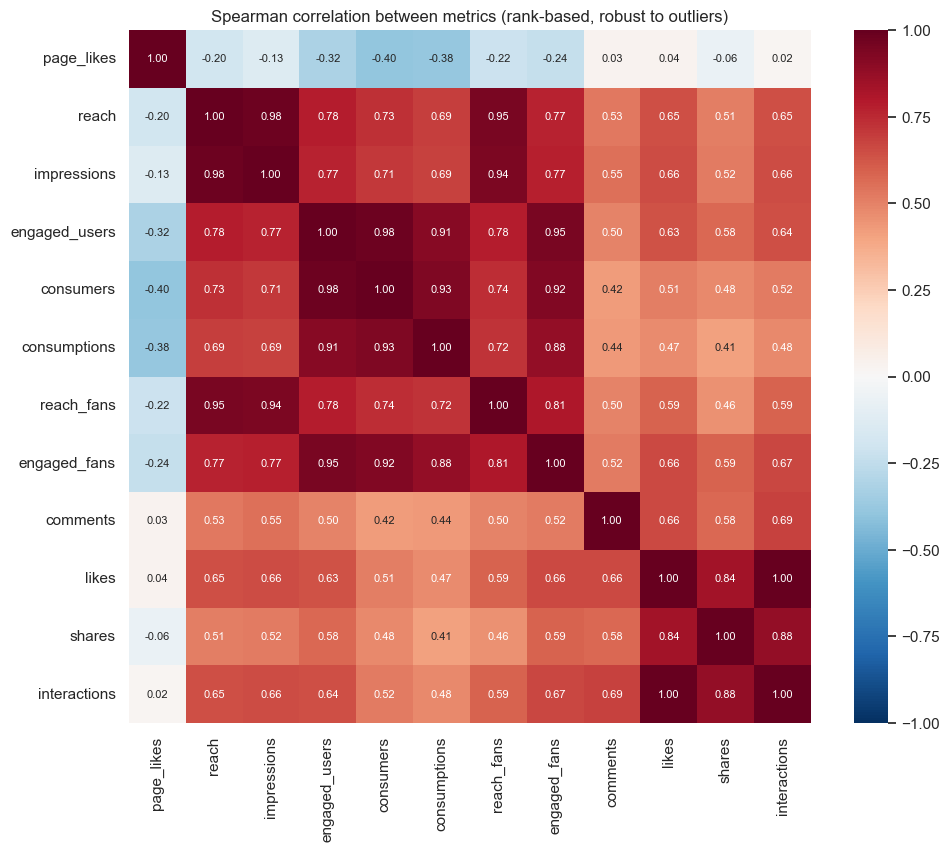

In [23]:
metrics = ['page_likes', 'reach', 'impressions', 'engaged_users', 'consumers', 'consumptions',
           'reach_fans', 'engaged_fans', 'comments', 'likes', 'shares', 'interactions']
corr = df[metrics].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Spearman correlation between metrics (rank-based, robust to outliers)')
plt.show()

In [24]:
corr['interactions'].drop('interactions').sort_values(ascending=False).round(2)

likes            1.00
shares           0.88
comments         0.69
engaged_fans     0.67
impressions      0.66
reach            0.65
engaged_users    0.64
reach_fans       0.59
consumers        0.52
consumptions     0.48
page_likes       0.02
Name: interactions, dtype: float64

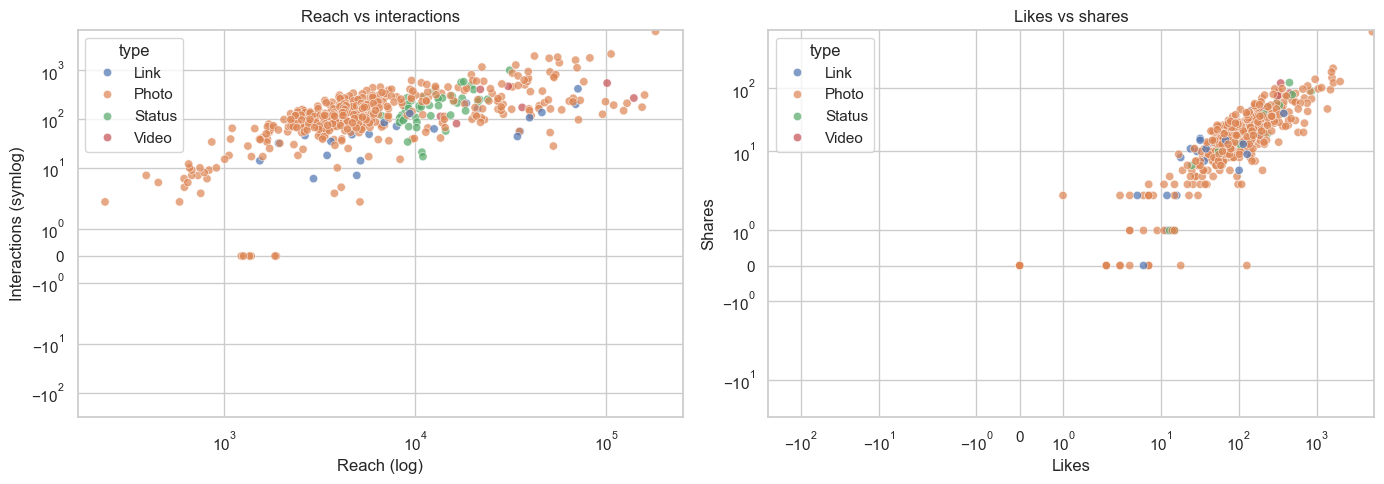

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='reach', y='interactions', hue='type', ax=axes[0], alpha=0.7)
axes[0].set(xscale='log', yscale='symlog', title='Reach vs interactions', xlabel='Reach (log)', ylabel='Interactions (symlog)')
sns.scatterplot(data=df, x='likes', y='shares', hue='type', ax=axes[1], alpha=0.7)
axes[1].set(xscale='symlog', yscale='symlog', title='Likes vs shares', xlabel='Likes', ylabel='Shares')
plt.tight_layout(); plt.show()

In [26]:
interaction_mix = df[['comments', 'likes', 'shares']].sum()
print((interaction_mix / interaction_mix.sum() * 100).round(1))
print()
print('Top 5 posts by interactions:')
df.nlargest(5, 'interactions')[['type', 'category_name', 'paid', 'month', 'hour', 'reach', 'interactions']]

comments     3.5
likes       83.7
shares      12.8
dtype: float64

Top 5 posts by interactions:


,type,category_name,paid,month,hour,reach,interactions
244,Photo,Product (ads),Paid,7,5,180480,6334
379,Photo,Inspiration,Paid,4,14,105632,2177
168,Photo,Action (offers),Organic,9,10,41984,1974
460,Photo,Inspiration,Organic,2,13,55520,1873
349,Photo,Inspiration,Organic,5,13,81856,1806


## 9. Key insights and conclusions

### Cleaning summary
- Only 5 values were missing:
  - 1 `like` and 4 `share` values were filled with 0. This is safe because `Total Interactions` equals comments + likes + shares on every row after filling.
  - 1 `Paid` flag was filled with the most common value (not paid).
- No duplicate rows were found.
- Column names were shortened. Category codes were mapped to names: 1 = Action (special offers), 2 = Product (ads), 3 = Inspiration.
- Rate metrics were added so that posts with different reach can be compared fairly:
  - engagement rate = engaged users ÷ reach
  - interaction rate = interactions ÷ reach
  - virality = shares ÷ interactions

### Key findings
1. **Skewed performance:** a typical post reaches 5,281 people (median) and gets 124 interactions. The means are much higher (13,903 reach and 212 interactions) because a few posts go viral. The best post reached 180,480 people and got 6,334 interactions.
2. **Content mix:** 85% of posts are photos, 9% statuses, 4% links and 1% videos.
3. **Post type:**

   | Post type | Median reach | Median interactions | Engagement rate |
   |---|---|---|---|
   | Video (7 posts) | 30,624 | 271 | 3.2% |
   | Status | 11,096 | 186 | 15.5% (highest) |
   | Photo | 4,675 | 122 | 12.3% |
   | Link | 7,422 | 53 | 2.3% |

   - **Videos** have the highest median reach and interactions, but only 7 videos were posted, so this result is uncertain.
   - **Status** posts give the best balance: high reach and the highest engagement rate.
   - **Photos** are the most used type but perform in the middle.
   - **Links** perform worst.
4. **Category:**
   - Inspiration posts (163 median interactions, highest virality at 16%) and Product posts (153 interactions, 14.3% engagement rate) do clearly better than Action/offer posts (87 interactions, 9.1% engagement rate).
   - Action is the most frequent category (215 posts), so the most-used category is the weakest.
5. **Paid promotion:**
   - Paid posts have about 46% more median reach than organic ones (7,132 vs 4,898) and more interactions (158 vs 117).
   - Their engagement rate is about the same (11.8% vs 12.3%). Paying buys more reach, but it does not make the content more engaging.
6. **Timing:**
   - Among hours with at least 10 posts, 13:00 (median 155 interactions), 10:00 and 03:00 perform best. 08:00 and 12:00 perform worst.
   - The differences between hours are moderate and based on small groups, so timing matters less than post type and category.
7. **Audience growth vs reach:**
   - Page likes grew 60% during 2014 (86,909 → 139,441).
   - Median reach per post did not grow, and October was the lowest month (2,955). More fans did not automatically bring more reach per post.
8. **Relationships between metrics:**
   - Likes make up 84% of all interactions, shares 13% and comments 3.5%.
   - Interactions are strongly linked to shares (Spearman 0.88) and comments (0.69), and moderately to reach (0.65).
   - Page size has almost no relationship with interactions (0.02).

### Recommendations for content planning
- Post more **status updates and videos** and fewer plain links. Test videos at larger volume to confirm their strong but small-sample results.
- Shift the mix from discount/offer posts towards **inspiration and product** content, which earns more engagement and shares.
- Use **paid promotion to extend reach** for posts that already perform well organically, because paying does not improve engagement rate.
- Schedule key posts around **10:00–13:00**, and keep testing timing because the effect is small.
- Track **engagement rate and shares**, not only page likes. Growing the fan base did not increase reach per post.

### Limitations
- The sample is 500 posts from one brand in one year (part of the original 790 posts).
- Some groups are very small (7 videos, 22 links).
- Weekday is only available as a code (1–7).
- All findings are correlations, not proof of cause.
